**Nota (corrección posterior).** El "BERT sin fine-tuning" de este cuaderno es en realidad el BERT en inglés del notebook 04 (`models/bert_finetuned`, entrenado con Fake & Real News), aplicado al corpus ecuatoriano sin adaptarlo al español. Por eso es una prueba de transferencia sin adaptación, no una ausencia de fine-tuning. Además, el texto en español pasó por el preprocesamiento diseñado para inglés (`src/preprocessing.py`) y se evaluó sobre los 1,543 artículos completos. Su accuracy (66.62%) no es comparable con la del notebook 08, que evalúa otro modelo sobre otro conjunto. La comparación de modelos en español, con validación cruzada y líneas base, está en el notebook 10.

In [2]:
# ================================================
# Notebook 07: Corpus Ecuatoriano
# Autor: Steeven Quezada
# Fuente: Ecuador Chequea (ecuadorchequea.com)
# Método: WordPress REST API
# Total: 3,799 verificaciones (2016-2026)
# ================================================

import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Cargar corpus
df = pd.read_csv('../data/external/corpus_ecuador_chequea.csv')
print(f"Corpus ecuatoriano cargado: {len(df):,} artículos")
print(f"\nColumnas: {df.columns.tolist()}")
print(f"\nDistribución inicial de etiquetas:")
print(df['etiqueta'].value_counts())
print(f"\nRango temporal:")
print(f"  Desde: {df['fecha'].min()}")
print(f"  Hasta: {df['fecha'].max()}")

Corpus ecuatoriano cargado: 3,799 artículos

Columnas: ['titulo', 'contenido', 'etiqueta', 'fecha', 'url']

Distribución inicial de etiquetas:
etiqueta
OTROS        2256
FALSO        1088
CIERTO        221
ENGAÑOSO      168
IMPRECISO      64
VERDADERO       2
Name: count, dtype: int64

Rango temporal:
  Desde: 2016-10-24
  Hasta: 2026-09-02


In [3]:
# ================================================
# PASO 2: FILTRAR Y PREPARAR CORPUS FINAL
# ================================================

# Descartar OTROS
df_clean = df[df['etiqueta'] != 'OTROS'].copy()
df_clean = df_clean.reset_index(drop=True)

print(f"Artículos con etiqueta confiable: {len(df_clean):,}")
print(f"Artículos descartados (OTROS):    {len(df) - len(df_clean):,}")

# Crear etiqueta binaria para el modelo
# 0 = Desinformación (FALSO + ENGAÑOSO + IMPRECISO)
# 1 = Verificado (CIERTO + VERDADERO)
df_clean['label_binario'] = df_clean['etiqueta'].map({
    'FALSO':        0,
    'ENGAÑOSO':     0,
    'IMPRECISO':    0,
    'FALTA CONTEXTO': 0,
    'CIERTO':       1,
    'VERDADERO':    1,
})

print(f"\n=== CORPUS FINAL ===")
print(f"Desinformación (label=0): {(df_clean['label_binario']==0).sum():,}")
print(f"Verificado     (label=1): {(df_clean['label_binario']==1).sum():,}")
print(f"\nDistribución detallada:")
print(df_clean['etiqueta'].value_counts())

# Guardar corpus final
df_clean.to_csv('../data/external/corpus_ecuador_final.csv',
                index=False, encoding='utf-8-sig')
print(f"\n✓ Corpus final guardado: data/external/corpus_ecuador_final.csv")

Artículos con etiqueta confiable: 1,543
Artículos descartados (OTROS):    2,256

=== CORPUS FINAL ===
Desinformación (label=0): 1,320
Verificado     (label=1): 223

Distribución detallada:
etiqueta
FALSO        1088
CIERTO        221
ENGAÑOSO      168
IMPRECISO      64
VERDADERO       2
Name: count, dtype: int64

✓ Corpus final guardado: data/external/corpus_ecuador_final.csv


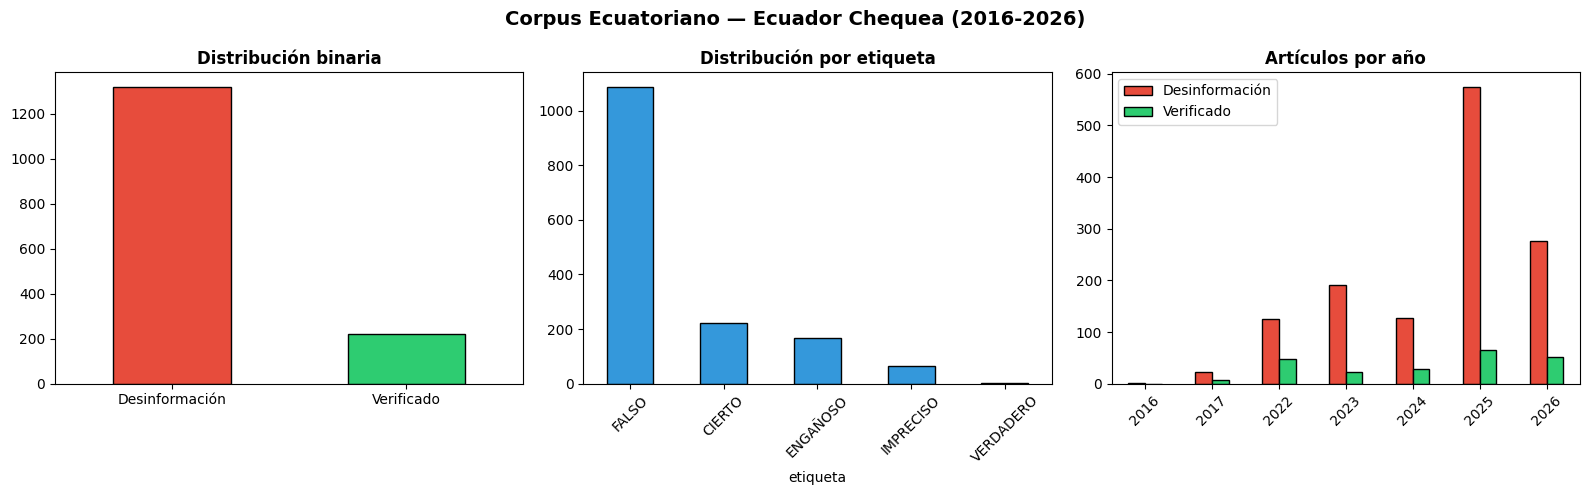

=== ESTADÍSTICAS DEL CORPUS ===
Longitud promedio del contenido: 721 palabras
Rango temporal: 2016-10-24 → 2026-09-02
Años cubiertos: 7


In [4]:
# ================================================
# PASO 3: ANÁLISIS EXPLORATORIO DEL CORPUS
# ================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Distribución binaria
df_clean['label_binario'].value_counts().plot(
    kind='bar', ax=axes[0],
    color=['#E74C3C', '#2ECC71'], edgecolor='black'
)
axes[0].set_title('Distribución binaria', fontweight='bold')
axes[0].set_xticklabels(['Desinformación', 'Verificado'], rotation=0)
axes[0].set_xlabel('')

# 2. Distribución por etiqueta
df_clean['etiqueta'].value_counts().plot(
    kind='bar', ax=axes[1], edgecolor='black', color='#3498DB'
)
axes[1].set_title('Distribución por etiqueta', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

# 3. Evolución temporal
df_clean['año'] = pd.to_datetime(df_clean['fecha']).dt.year
df_clean.groupby(['año', 'label_binario']).size().unstack(fill_value=0).plot(
    kind='bar', ax=axes[2],
    color=['#E74C3C', '#2ECC71'], edgecolor='black'
)
axes[2].set_title('Artículos por año', fontweight='bold')
axes[2].set_xlabel('')
axes[2].legend(['Desinformación', 'Verificado'])
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Corpus Ecuatoriano — Ecuador Chequea (2016-2026)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/13_corpus_ecuatoriano.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Estadísticas de texto
df_clean['longitud_contenido'] = df_clean['contenido'].str.split().str.len()
print("=== ESTADÍSTICAS DEL CORPUS ===")
print(f"Longitud promedio del contenido: {df_clean['longitud_contenido'].mean():.0f} palabras")
print(f"Rango temporal: {df_clean['fecha'].min()} → {df_clean['fecha'].max()}")
print(f"Años cubiertos: {df_clean['año'].nunique()}")

In [5]:
# ================================================
# PASO 4: RESUMEN FINAL DEL CORPUS
# ================================================

print("=" * 55)
print("RESUMEN — CORPUS ECUATORIANO DE DESINFORMACIÓN")
print("=" * 55)
print(f"Fuente:           Ecuador Chequea (ecuadorchequea.com)")
print(f"Método:           WordPress REST API")
print(f"Total descargado: 3,799 artículos")
print(f"Descartados:      2,256 (etiqueta no confiable)")
print(f"Corpus final:     1,543 artículos")
print(f"")
print(f"Distribución:")
print(f"  Desinformación: 1,320 (85.5%)")
print(f"  Verificado:       223 (14.5%)")
print(f"")
print(f"Rango temporal:   2016 — 2026")
print(f"Longitud promedio: {df_clean['longitud_contenido'].mean():.0f} palabras por artículo")
print(f"")
print(f"Limitaciones:")
print(f"  → Desbalance de clases (85/15)")
print(f"  → Gap temporal 2018-2021")
print(f"  → Contenido en español (requiere modelo específico)")
print(f"")
print(f"✓ Corpus guardado: data/external/corpus_ecuador_final.csv")
print(f"✓ Visualización:   reports/13_corpus_ecuatoriano.png")

RESUMEN — CORPUS ECUATORIANO DE DESINFORMACIÓN
Fuente:           Ecuador Chequea (ecuadorchequea.com)
Método:           WordPress REST API
Total descargado: 3,799 artículos
Descartados:      2,256 (etiqueta no confiable)
Corpus final:     1,543 artículos

Distribución:
  Desinformación: 1,320 (85.5%)
  Verificado:       223 (14.5%)

Rango temporal:   2016 — 2026
Longitud promedio: 721 palabras por artículo

Limitaciones:
  → Desbalance de clases (85/15)
  → Gap temporal 2018-2021
  → Contenido en español (requiere modelo específico)

✓ Corpus guardado: data/external/corpus_ecuador_final.csv
✓ Visualización:   reports/13_corpus_ecuatoriano.png


In [6]:
# ================================================
# PASO 5: EVALUACIÓN DEL MODELO BERT
# SOBRE EL CORPUS ECUATORIANO
# ================================================
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
import sys
sys.path.append('../src')
from preprocessing import preprocess

print("Cargando modelo BERT fine-tuned...")
MODEL_PATH = '../models/bert_finetuned/'
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
model     = model.to(DEVICE)
model.eval()

print(f"✓ Modelo cargado en: {DEVICE}")
print(f"✓ Corpus ecuatoriano: {len(df_clean):,} artículos")

Cargando modelo BERT fine-tuned...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Modelo cargado en: cpu
✓ Corpus ecuatoriano: 1,543 artículos


In [7]:
# ================================================
# PASO 6: PREPROCESAMIENTO Y EVALUACIÓN
# ================================================
import warnings
warnings.filterwarnings('ignore')

# Preprocesar corpus ecuatoriano
print("Preprocesando corpus ecuatoriano...")
print("Esto puede tardar unos minutos...\n")

df_clean['texto_clean'] = df_clean['contenido'].apply(
    lambda x: preprocess(str(x), lemmatize=True)
)

print(f"✓ Preprocesamiento completado")
print(f"  Textos vacíos: {(df_clean['texto_clean'].str.strip()=='').sum()}")

# Tokenizar
print("\nTokenizando...")
MAX_LENGTH = 256

encodings = tokenizer(
    list(df_clean['texto_clean']),
    max_length=MAX_LENGTH,
    padding=True,
    truncation=True,
    return_tensors='pt'
)

print(f"✓ Tokenización completada: {encodings['input_ids'].shape}")

Preprocesando corpus ecuatoriano...
Esto puede tardar unos minutos...

✓ Preprocesamiento completado
  Textos vacíos: 0

Tokenizando...
✓ Tokenización completada: torch.Size([1543, 256])


In [8]:
# ================================================
# PASO 7: PREDICCIÓN Y MÉTRICAS
# ================================================
import numpy as np

class CorpusDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels    = labels.reset_index(drop=True)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx].clone().detach() 
                for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# Crear dataset y dataloader
dataset    = CorpusDataset(encodings, df_clean['label_binario'])
dataloader = DataLoader(dataset, batch_size=16, shuffle=False)

# Predecir
print("Evaluando modelo BERT sobre corpus ecuatoriano...")
all_preds, all_labels = [], []

with torch.no_grad():
    for i, batch in enumerate(dataloader):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['labels'].to(DEVICE)

        outputs = model(input_ids=input_ids, 
                       attention_mask=attention_mask)
        preds   = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        if (i+1) % 10 == 0:
            print(f"  Batch {i+1}/{len(dataloader)}...")

# Métricas
acc = accuracy_score(all_labels, all_preds)
f1  = f1_score(all_labels, all_preds, average='weighted')

print(f"\n=== RESULTADOS BERT EN CORPUS ECUATORIANO ===")
print(f"Accuracy:  {acc*100:.2f}%")
print(f"F1-score:  {f1:.4f}")
print(f"\nReporte detallado:")
print(classification_report(all_labels, all_preds,
      target_names=['Desinformación', 'Verificado']))
print(f"\nComparación:")
print(f"  BERT en inglés (Kaggle):     99.91%")
print(f"  BERT en español (Ecuador):   {acc*100:.2f}%")
print(f"  Diferencia:                  {(acc - 0.9991)*100:+.2f} puntos")

Evaluando modelo BERT sobre corpus ecuatoriano...
  Batch 10/97...
  Batch 20/97...
  Batch 30/97...
  Batch 40/97...
  Batch 50/97...
  Batch 60/97...
  Batch 70/97...
  Batch 80/97...
  Batch 90/97...

=== RESULTADOS BERT EN CORPUS ECUATORIANO ===
Accuracy:  66.62%
F1-score:  0.7041

Reporte detallado:
                precision    recall  f1-score   support

Desinformación       0.86      0.73      0.79      1320
    Verificado       0.15      0.29      0.20       223

      accuracy                           0.67      1543
     macro avg       0.51      0.51      0.50      1543
  weighted avg       0.76      0.67      0.70      1543


Comparación:
  BERT en inglés (Kaggle):     99.91%
  BERT en español (Ecuador):   66.62%
  Diferencia:                  -33.29 puntos


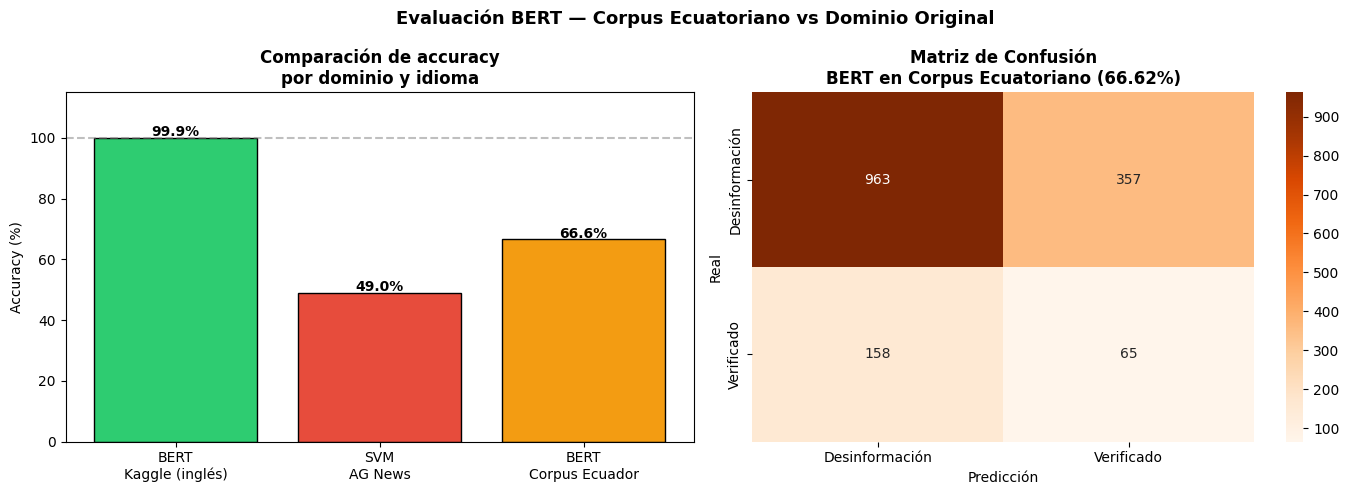


=== CONCLUSIÓN ===

El modelo BERT entrenado en inglés cae 33 puntos al evaluar
sobre el corpus ecuatoriano en español (99.91% → 66.62%).

Esto confirma la necesidad de fine-tuning con datos locales.
El bajo recall en clase 'Verificado' (29%) indica que el modelo
clasifica la mayoría del contenido como desinformación cuando
no encuentra señales del dominio de entrenamiento (ej: 'reuters').

Próximo paso: fine-tuning de BERT con el corpus ecuatoriano.



In [ ]:
# ================================================
# PASO 8: VISUALIZACIÓN RESULTADOS
# ================================================
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparación de accuracy
modelos = ['BERT\nKaggle (inglés)', 'SVM\nAG News', 'BERT\nCorpus Ecuador']
accuracies = [99.91, 49.0, 66.62]
colores = ['#2ECC71', '#E74C3C', '#F39C12']

bars = axes[0].bar(modelos, accuracies, color=colores, edgecolor='black')
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.5,
                f'{acc:.1f}%', ha='center', fontweight='bold')
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Comparación de accuracy\npor dominio y idioma', fontweight='bold')
axes[0].axhline(y=99.91, color='gray', linestyle='--', alpha=0.5)

# Matriz de confusión
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Desinformación', 'Verificado'],
            yticklabels=['Desinformación', 'Verificado'],
            ax=axes[1])
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')
axes[1].set_title(f'Matriz de Confusión\nBERT en Corpus Ecuatoriano (66.62%)',
                  fontweight='bold')

plt.suptitle('Evaluación BERT — Corpus Ecuatoriano vs Dominio Original',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/14_bert_corpus_ecuatoriano.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("\n=== CONCLUSIÓN ===")
print("""
El modelo BERT entrenado en inglés cae 33 puntos al evaluar
sobre el corpus ecuatoriano en español (99.91% → 66.62%).

Esto confirma la necesidad de fine-tuning con datos locales.
El bajo recall en clase 'Verificado' (29%) indica que el modelo
clasifica la mayoría del contenido como desinformación cuando
no encuentra señales del dominio de entrenamiento (ej: 'reuters').

Próximo paso: fine-tuning de BERT con el corpus ecuatoriano.
""")